In [ ]:
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.optimize import newton
from scipy.optimize import bisect

In [ ]:
# sample from a cosx + 1.2 distribution from 0 to 2pi
def f(x):
   return np.cos(x) + 1.2
    
# integral cosx + 1.2 from 0 to 2pi = 12pi/ 5
def pdf(x):
   return f(x) * 5 / ( 12 * np.pi)

def cdf(x):
    return 5 * (np.sin(x) + 1.2*x) / (12 * np.pi)

def inv_cdf(u):
   try:
      # root = newton(func=lambda x: 5*np.sin(x) + 6*x  - 12 * np.pi * u,
      #             x0 = 0,
      #             fprime = lambda x: 5 * np.cos(x) + 6
      #             )
      root = bisect(
         func=lambda x: 5*np.sin(x) + 6*x  - 12 * np.pi * u,
                  a= 0, 
                  b= 2* np.pi)
      return root
   except:
      print("fail to converge for value", u)
      return np.nan



C:\Users\power\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
C:\Users\power\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
C:\Users\power\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
C:\Users\power\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating

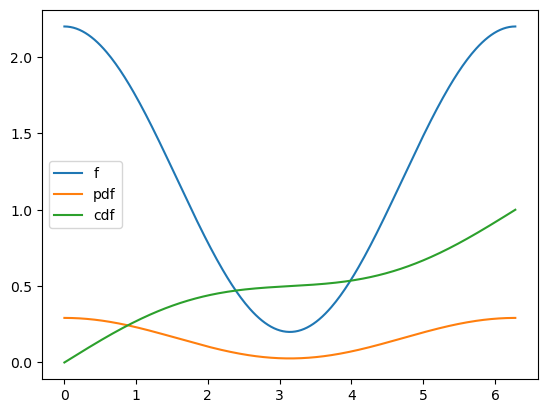

In [124]:
fig, ax = plt.subplots()
x = np.linspace(0, 2*np.pi, 300)
sns.lineplot(x=x, y = f(x), ax=ax, label="f")
sns.lineplot(x=x, y=pdf(x), ax=ax, label="pdf")
sns.lineplot(x=x, y= cdf(x), ax=ax, label="cdf")
plt.show()

fail to converge for value 2.946134356207703
fail to converge for value 0.13118699753635343
fail to converge for value 1.4012201596374245
fail to converge for value 2.7437776018049553
fail to converge for value 1.886806650358665
fail to converge for value 2.6064112320319643
fail to converge for value 4.865715303554194
fail to converge for value 5.822548985971294
fail to converge for value 0.522731156774044
fail to converge for value 2.460782744416514
fail to converge for value 0.19900616058927936
fail to converge for value 4.8183665805268765
fail to converge for value 2.3061441257348854
fail to converge for value 2.3595424259810636
fail to converge for value 6.230266866341424
fail to converge for value 4.976747788478813
fail to converge for value 2.9050346479480122
fail to converge for value 1.2646120019558595
fail to converge for value 1.688716213936184
fail to converge for value 3.796974627686886
fail to converge for value 5.406283249937986
fail to converge for value 3.54680745796448

<Axes: >

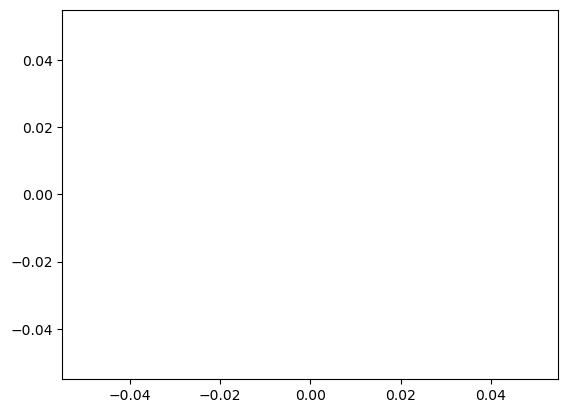

In [149]:
eps = 0.001
u = np.random.uniform(low= eps, high=2*np.pi - eps, size = (2000))
samples_from_f = np.array([inv_cdf(s) for s in u])
samples_from_f = samples_from_f[~np.isnan(samples_from_f)]
sns.histplot(samples_from_f, bins=50, stat="probability")

C:\Users\power\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
C:\Users\power\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
C:\Users\power\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
C:\Users\power\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating

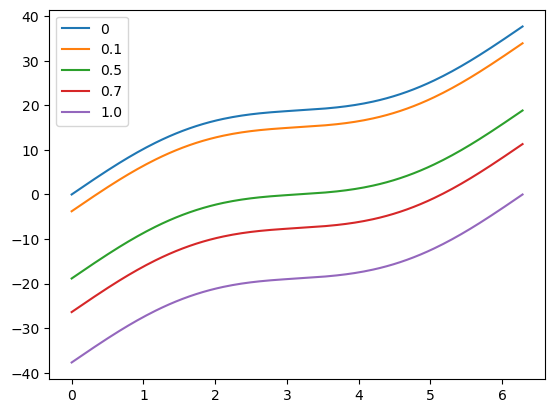

In [145]:
nf = lambda x, u: 5*np.sin(x) + 6*x  - 12 * np.pi * u

x = np.linspace(0, 2 * np.pi, num = 200)

fig, ax = plt.subplots()
for u in [0, 0.1, 0.5, 0.7, 1.0]:
    sns.lineplot(x=x, y = nf(x, u), ax=ax, label=str(u))
plt.show()